<a href="https://colab.research.google.com/github/NurSyahira02/Google-Colab/blob/main/AI_in_Practice_SVD_and_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**SVD**

1. Example 1

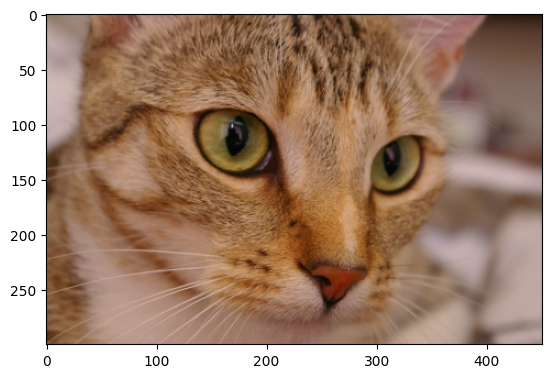

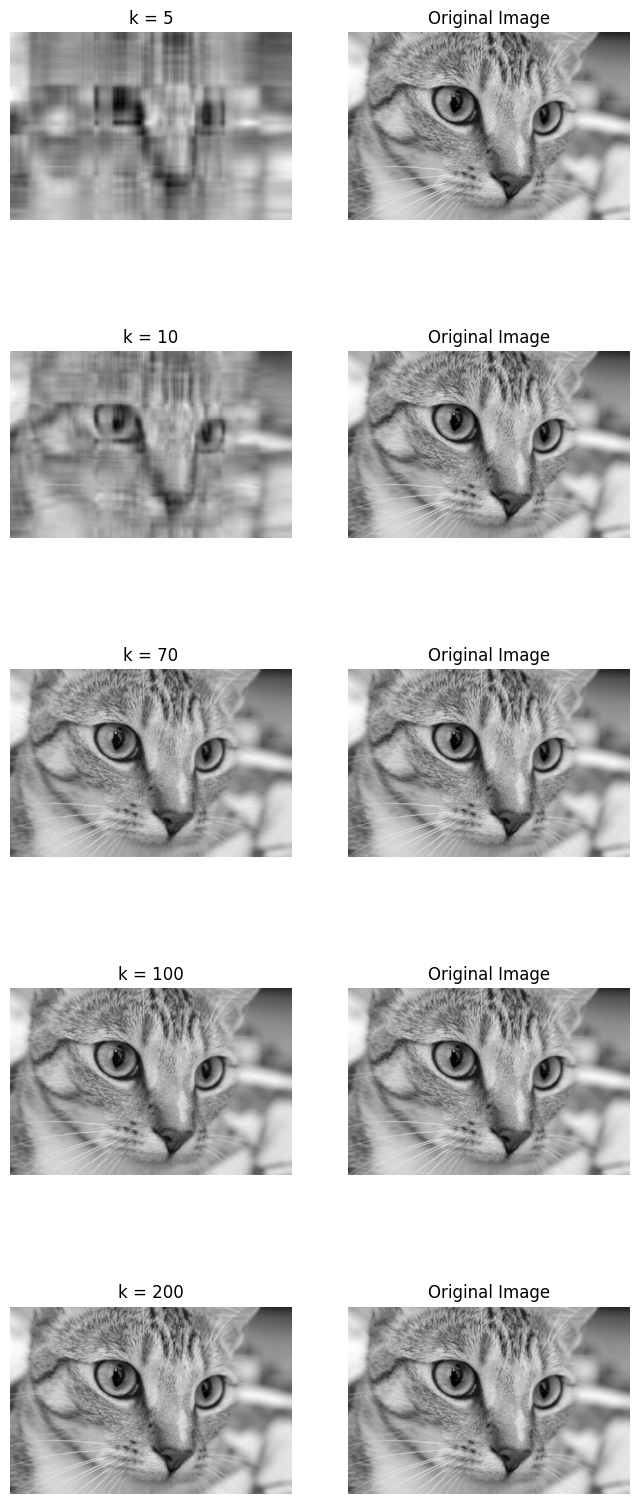

In [ ]:
from skimage.color import rgb2gray
from skimage import data
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import svd


"""
SVD on image compression
"""


cat = data.chelsea()
plt.imshow(cat)
# convert to grayscale
gray_cat = rgb2gray(cat)

# calculate the SVD and plot the image
U, S, V_T = svd(gray_cat, full_matrices=False)
S = np.diag(S)
fig, ax = plt.subplots(5, 2, figsize=(8, 20))

curr_fig = 0
for r in [5, 10, 70, 100, 200]:
    cat_approx = U[:, :r] @ S[0:r, :r] @ V_T[:r, :]
    ax[curr_fig][0].imshow(cat_approx, cmap='gray')
    ax[curr_fig][0].set_title("k = "+str(r))
    ax[curr_fig, 0].axis('off')
    ax[curr_fig][1].set_title("Original Image")
    ax[curr_fig][1].imshow(gray_cat, cmap='gray')
    ax[curr_fig, 1].axis('off')
    curr_fig += 1
plt.show()

2. Example 2

[[ 3  3  2]
 [ 2  3 -2]]
U:  [[-0.7815437 -0.6238505]
 [-0.6238505  0.7815437]]
Singular array [5.54801894 2.86696457]
V^{T} [[-0.64749817 -0.7599438  -0.05684667]
 [-0.10759258  0.16501062 -0.9804057 ]
 [-0.75443354  0.62869461  0.18860838]]
[[ 0.11462451  0.04347826]
 [ 0.07114625  0.13043478]
 [ 0.22134387 -0.26086957]]


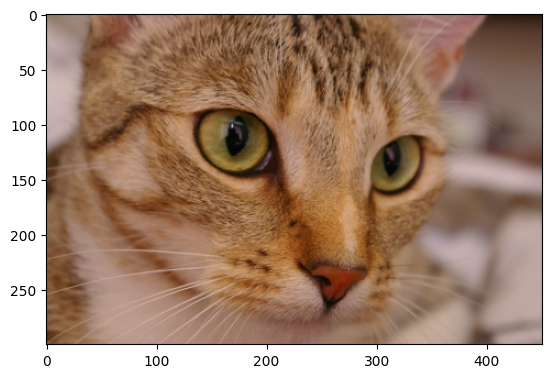

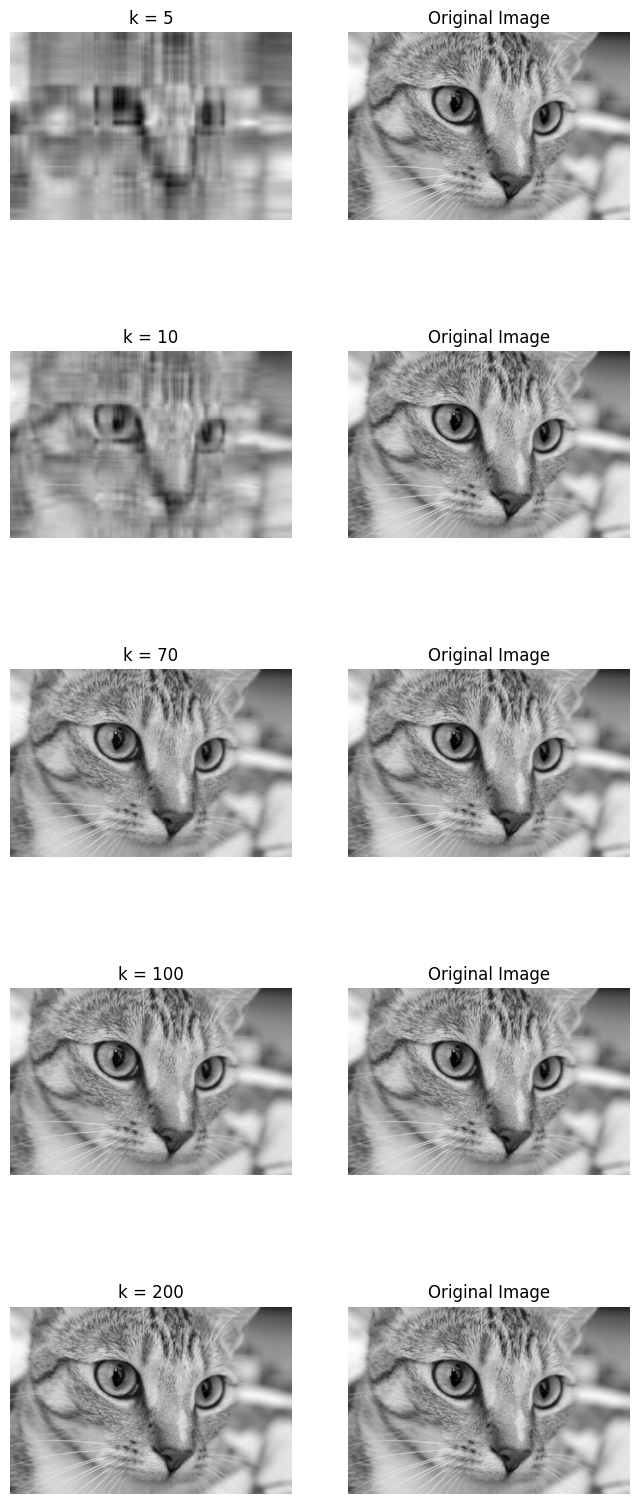

In [ ]:
# Imports

from skimage.color import rgb2gray
from skimage import data
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import svd

"""
Singular Value Decomposition
"""
# define a matrix
X = np.array([[3, 3, 2], [2, 3, -2]])
print(X)
# perform SVD
U, singular, V_transpose = svd(X)
# print different components
print("U: ", U)
print("Singular array", singular)
print("V^{T}", V_transpose)

"""
Calculate Pseudo inverse
"""
# inverse of singular matrix is just the reciprocal of each element
singular_inv = 1.0 / singular
# create m x n matrix of zeroes and put singular values in it
s_inv = np.zeros(X.shape)
s_inv[0][0] = singular_inv[0]
s_inv[1][1] = singular_inv[1]
# calculate pseudoinverse
M = np.dot(np.dot(V_transpose.T, s_inv.T), U.T)
print(M)

"""
SVD on image compression
"""


cat = data.chelsea()
plt.imshow(cat)
# convert to grayscale
gray_cat = rgb2gray(cat)

# calculate the SVD and plot the image
U, S, V_T = svd(gray_cat, full_matrices=False)
S = np.diag(S)
fig, ax = plt.subplots(5, 2, figsize=(8, 20))

curr_fig = 0
for r in [5, 10, 70, 100, 200]:
	cat_approx = U[:, :r] @ S[0:r, :r] @ V_T[:r, :]
	ax[curr_fig][0].imshow(cat_approx, cmap='gray')
	ax[curr_fig][0].set_title("k = "+str(r))
	ax[curr_fig, 0].axis('off')
	ax[curr_fig][1].set_title("Original Image")
	ax[curr_fig][1].imshow(gray_cat, cmap='gray')
	ax[curr_fig, 1].axis('off')
	curr_fig += 1
plt.show()

Exercise - change k values and change image

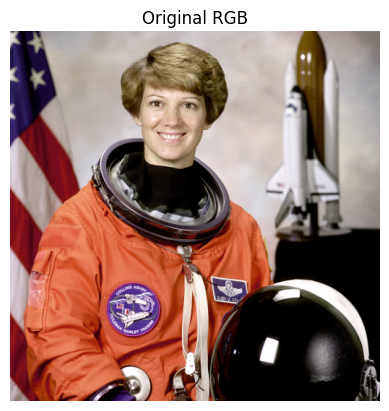

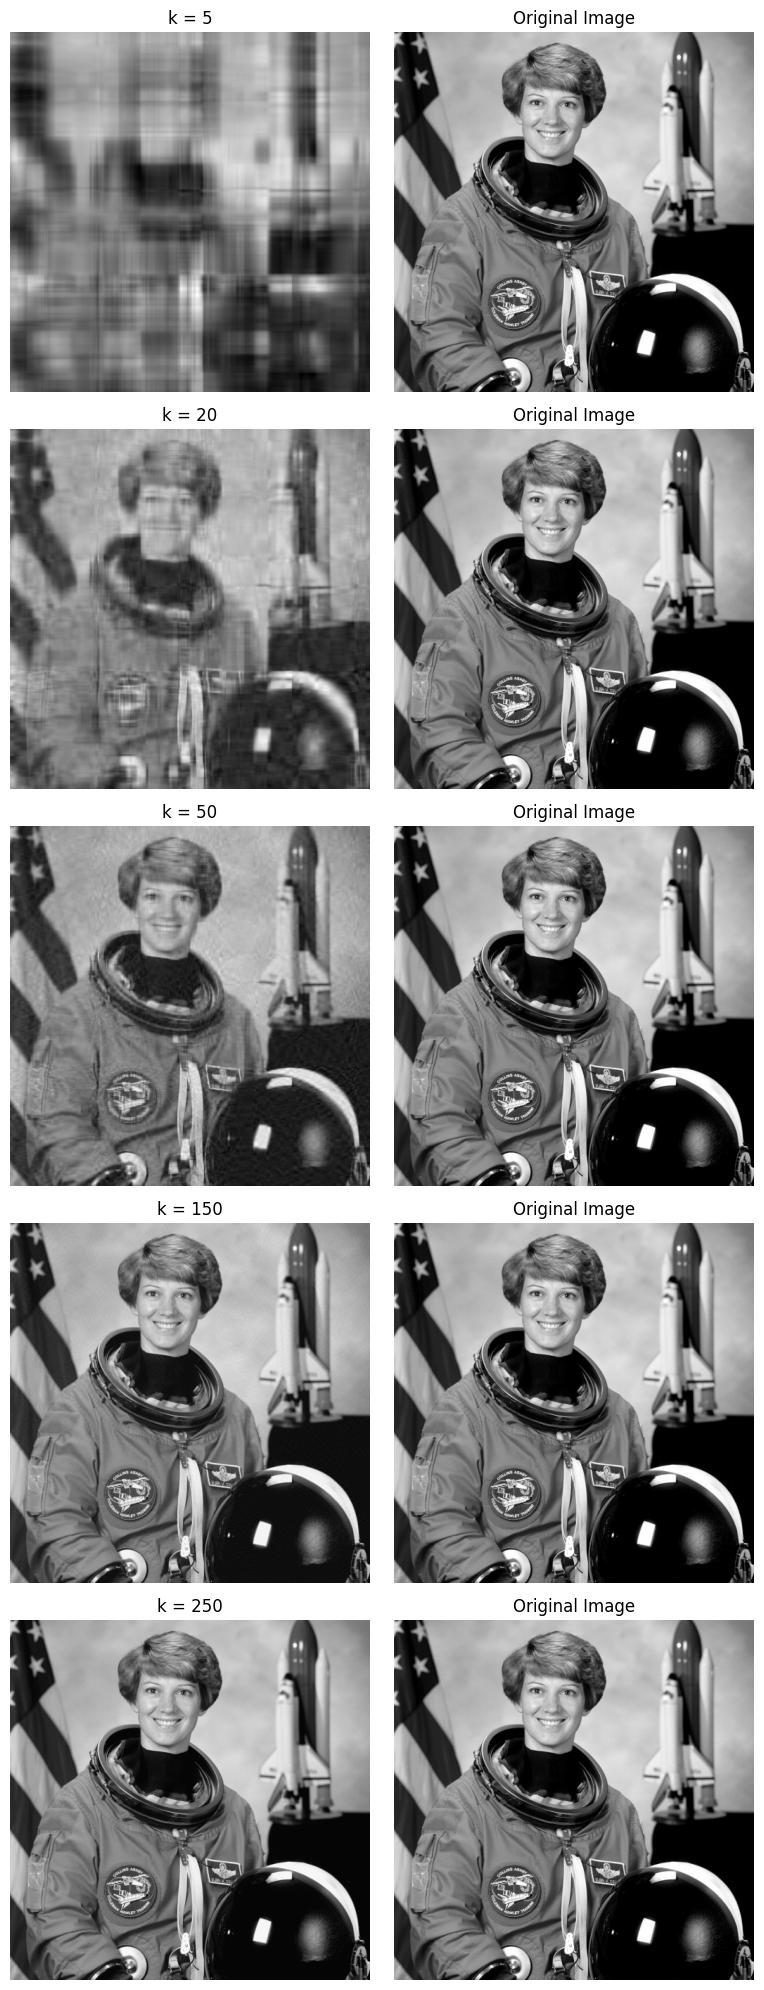

In [ ]:
from skimage.color import rgb2gray
from skimage import data
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import svd

"""
SVD on image compression (modified version)
"""

# --- CHANGE IMAGE HERE ---
img = data.astronaut()   # try: camera(), coffee(), rocket()
plt.imshow(img)
plt.title("Original RGB")
plt.axis("off")
plt.show()

# convert to grayscale
gray_img = rgb2gray(img)

# Calculate SVD
U, S, V_T = svd(gray_img, full_matrices=False)
S = np.diag(S)

# --- CHANGE COMPRESSION LEVELS HERE ---
k_values = [5, 20, 50, 150, 250]

fig, ax = plt.subplots(len(k_values), 2, figsize=(8, 20))

for i, k in enumerate(k_values):
    approx = U[:, :k] @ S[:k, :k] @ V_T[:k, :]
    ax[i][0].imshow(approx, cmap='gray')
    ax[i][0].set_title(f"k = {k}")
    ax[i][0].axis("off")

    ax[i][1].imshow(gray_img, cmap='gray')
    ax[i][1].set_title("Original Image")
    ax[i][1].axis("off")

plt.tight_layout()
plt.show()


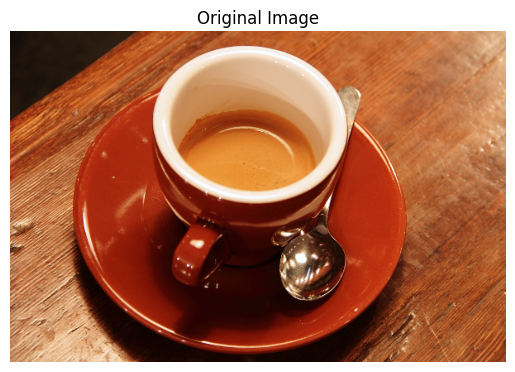

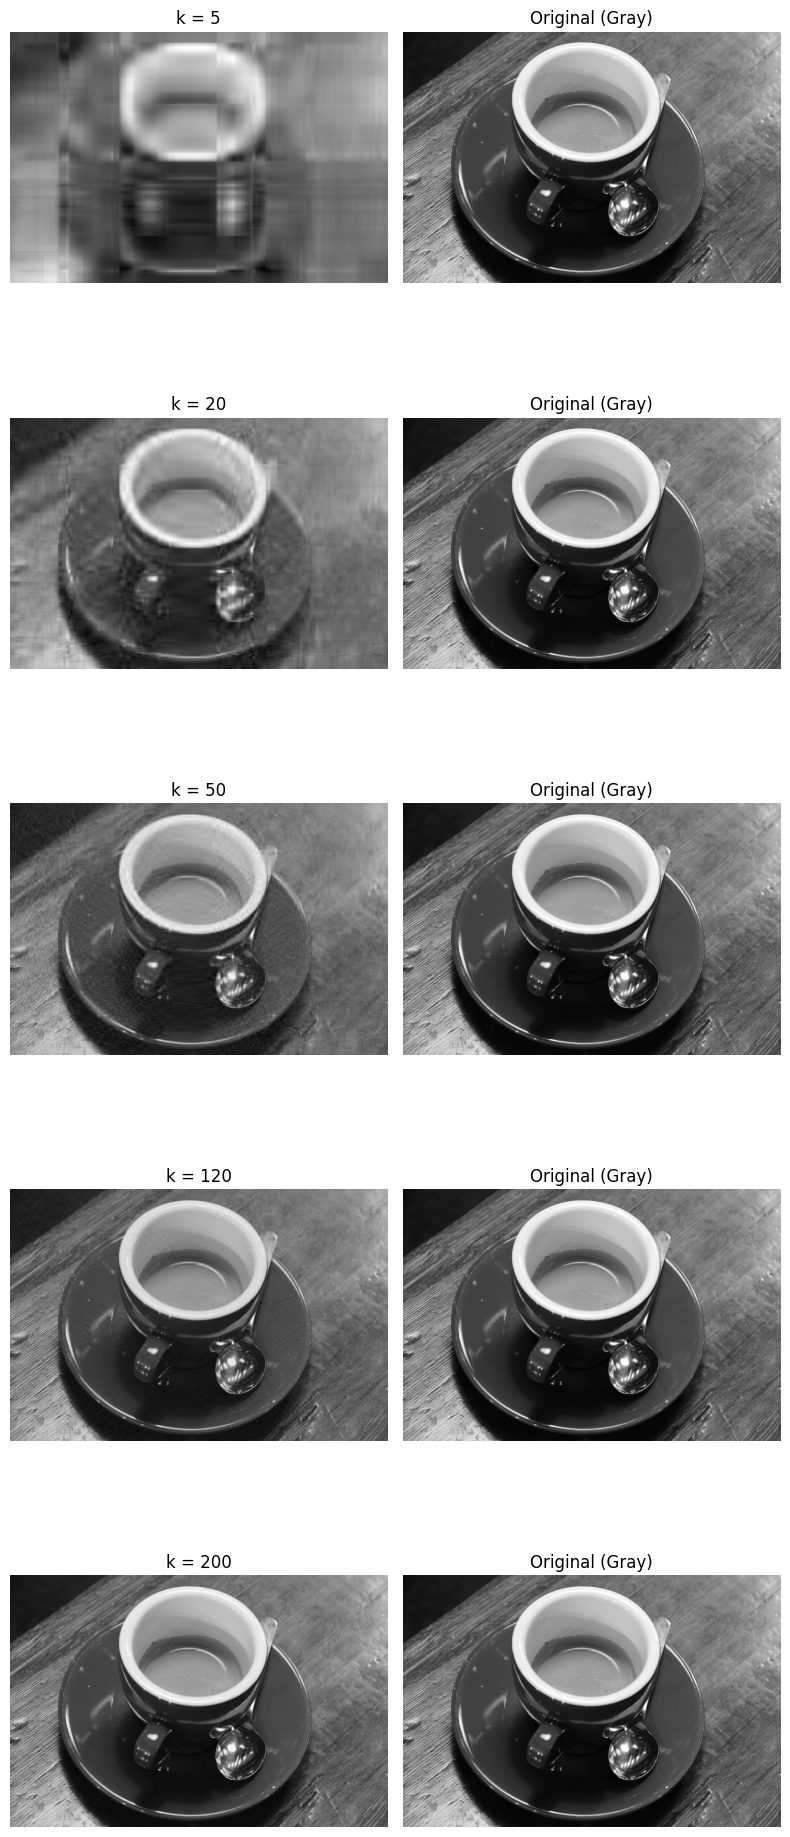

In [ ]:
from skimage.color import rgb2gray
from skimage import data
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import svd

# --- Change image here ---
img = data.coffee()     # try: coffee(), astronaut(), rocket(), camera()

# Show image
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Convert to gray
try:
    gray_img = rgb2gray(img)
except:
    gray_img = img  # for camera(), already grayscale

# SVD
U, S, V_T = svd(gray_img, full_matrices=False)
S = np.diag(S)

k_values = [5, 20, 50, 120, 200]

fig, ax = plt.subplots(len(k_values), 2, figsize=(8, 20))

for i, k in enumerate(k_values):
    approx = U[:, :k] @ S[:k, :k] @ V_T[:k, :]

    ax[i][0].imshow(approx, cmap='gray')
    ax[i][0].set_title(f"k = {k}")
    ax[i][0].axis("off")

    ax[i][1].imshow(gray_img, cmap='gray')
    ax[i][1].set_title("Original (Gray)")
    ax[i][1].axis("off")

plt.tight_layout()
plt.show()


**PCA**

Using wine dataset

Step 1: Importing the libraries

In [2]:
# importing required libraries,
import numpy as np #for math (this library handles numerical operations)
import matplotlib.pyplot as plt #for visualization/plot (Used to draw graphs)
import pandas as pd #fordataanalysis - PCA (Used for loading, cleaning, and manipulating datasets)

Step 2: Importing the dataset

In [4]:
# importing or loading the dataset
from sklearn.datasets import load_wine

wine_data = load_wine()

# distributing the dataset into two components X and Y
X = wine_data.data
y = wine_data.target

Step 3: Splitting the dataset into the training set and test set

In [5]:
# Splitting the X and Y into the
# Training set and Testing set
from sklearn.model_selection import train_test_split

#train_test_split - to split datasets into random train and test subsets.
#20% of the data will be used as the testing set.
#80% of the data will be used as the training set.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

Step 4: Feature Scaling

In [6]:
# performing preprocessing part
from sklearn.preprocessing import StandardScaler #used for feature scaling
sc = StandardScaler() #standardizes features by removing the mean & scaling to unit variance

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test) #Applies the same scaling parameters

Step 5: Applying PCA function

In [7]:
# Applying PCA function on training
# and testing set of X component
from sklearn.decomposition import PCA

pca = PCA(n_components = 2) #Reduce the dataset to 2 principal components

X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

explained_variance = pca.explained_variance_ratio_

Step 6: Fitting logistic regression to the training

In [8]:
# Fitting Logistic Regression To the training set
#supervised classification algorithm used to predict categorical outcomes
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(random_state = 0) #Creates an instance of the LogisticRegression classifier
classifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

Step 7: Predicting the test set result

In [9]:
# Predicting the test set result using
# predict function under LogisticRegression
y_pred = classifier.predict(X_test) #to predict the class labels for the input data

Step 8: Making the confusion matrix

In [10]:
# making confusion matrix between
# test set of Y and predicted value.
from sklearn.metrics import confusion_matrix #used to evaluate classification models

cm = confusion_matrix(y_test, y_pred) #Compares predicted vs actual labels and returns a matrix of shape

Step 9: Predicting the training set result

/tmp/ipykernel_784/3487951214.py:20: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


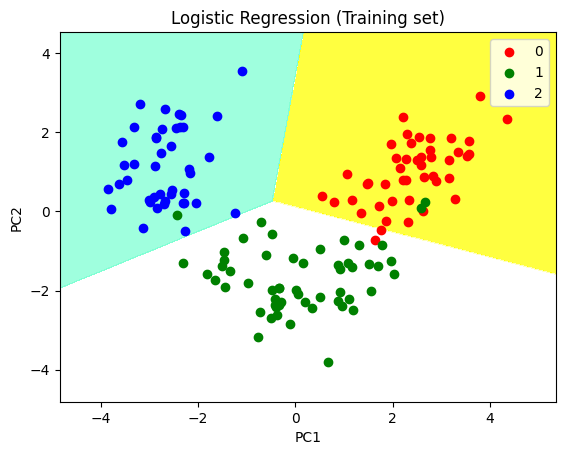

In [11]:
# Predicting the training set
# result through scatter plot
##allows creating custom color maps for plotting different classes with different colors
from matplotlib.colors import ListedColormap

X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, #creates evenly spaced values along each axis
					stop = X_set[:, 0].max() + 1, step = 0.01), #first principal component (PC1)
					np.arange(start = X_set[:, 1].min() - 1,
					stop = X_set[:, 1].max() + 1, step = 0.01)) #second principal component (PC2)

plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(),
			X2.ravel()]).T).reshape(X1.shape), alpha = 0.75, #sets transparency of regions
			cmap = ListedColormap(('yellow', 'white', 'aquamarine'))) #colors for the 3 classes

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
	plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
				c = ListedColormap(('red', 'green', 'blue'))(i), label = j)

plt.title('Logistic Regression (Training set)')
plt.xlabel('PC1') # for Xlabel
plt.ylabel('PC2') # for Ylabel
plt.legend() # to show legend

# show scatter plot
plt.show()


Step 10: Visualizing the test set results

/tmp/ipykernel_784/902737297.py:19: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], #PC1 and PC2 values for class j


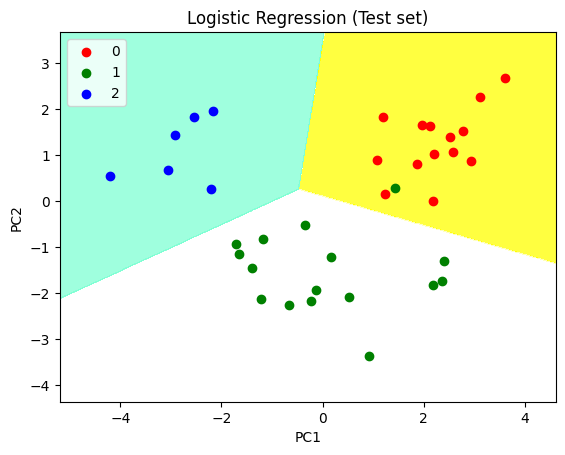

In [12]:
# Visualising the Test set results through scatter plot
from matplotlib.colors import ListedColormap #to assign custom colors to different classes in the plot

X_set, y_set = X_test, y_test

X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1,
					stop = X_set[:, 0].max() + 1, step = 0.01),
					np.arange(start = X_set[:, 1].min() - 1,
					stop = X_set[:, 1].max() + 1, step = 0.01))

plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(),
			X2.ravel()]).T).reshape(X1.shape), alpha = 0.75,
			cmap = ListedColormap(('yellow', 'white', 'aquamarine')))

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
	plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], #PC1 and PC2 values for class j
				c = ListedColormap(('red', 'green', 'blue'))(i), label = j)

# title for scatter plot
plt.title('Logistic Regression (Test set)') #Adds plot title, axis labels, and legend
plt.xlabel('PC1') # for Xlabel
plt.ylabel('PC2') # for Ylabel
plt.legend()

# show scatter plot
plt.show()